# Full hydraulic injection tomography


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测到目标核查卡

当前存在 `data/raw_data.npz`；所述获取/估计路径由本地代码实现。

任务 `hydraulic_injection_conductivity` 的观测定义：当前raw_data.npz的实际键、形状、dtype与README单位说明：hydraulic_head (1, 30, 29) float64：Measured hydraulic heads, m; batch, injection experiment, observation well；well_indices (1, 30, 2) int64：Known zero-based row,column well locations, cell index; also defines experiment order。恢复目标：完整75x100 log hydraulic conductivity，log(K/(1m/day))。

获取模型：Darcy流椭圆PDE在已知注入/边界下，通过harmonic finite-volume transmissivity生成heads。实际恢复算法：solvers.reconstruct：prior eigenmodes、有限差分Jacobian、PCGA/Gauss-Newton及line search。语义类型为 `inverse_spatial`；其中闭式逆也属于反问题，但内部制造观测或缺输入的限制见下文。

真值情况：独立于本次重建的仿真设定真值；test/validation.md:5的true_logK.txt是独立原始设定，另有hash与观测对应，不是估计baseline。评估方法参考与仪器校准均不能当作独立物理真值。

现有实验和图：hydraulic_injection_conductivity.ipynb单元3有保存图；ax[0].scatter(xy[:,0],xy[:,1],s=20,c=np.arange(30),cmap='viridis');ax[0].set_xlim(0,1000);ax[0].set_ylim(0,750);ax[0].set_aspect('equal');ax[0].set_xlabel('x / m');ax[0].set_ylabel；hydraulic_injection_conductivity.ipynb单元6有保存图；ax[0].semilogy(np.arange(1,len(fresh['eigenvalues'])+1),fresh['eigenvalues'],'o-',ms=3);ax[0].set_xlabel('Prior mode');ax[0].set_ylabel('Covariance eigenvalue');ax[0].set_title('Co；hydraulic_injection_conductivity.ipynb单元7：Results；hydraulic_injection_conductivity.ipynb单元8有保存图；im=a.imshow(arr,origin='lower',extent=extent,cmap='viridis',vmin=low,vmax=high);a.set_title(title,fontsize=10);fig.colorbar(im,ax=a,label='ln(K / (m/day))')；hydraulic_injection_conductivity.ipynb单元10有保存图；im=a.imshow(arr,origin='lower',extent=extent,vmin=0,vmax=upper,cmap='cividis');a.set_title(title,fontsize=10);fig.colorbar(im,ax=a,label='Log-field variance')；hydraulic_injection_conductivity.ipynb单元11有保存图；图内容由该单元调用的本地visualization函数生成。图/比较代码位于单元3, 6, 8, 10, 11（从0计数）。代码单元6个，带execution_count的6个，保存PNG输出6幅；本审计未重新运行。

现有输出来自历史执行；本次未复跑。

限制与缺口：本次为静态语义与证据核查，未重新验证数值正确性或运行结果。

<!-- inverse-evidence-audit:20261026:end -->


## Problem
Recover every cell of the75×100log-conductivity field from870heads in30known injection experiments. This is a nonlinear spatial inverse problem. Actual author simulation truth permits field-error evaluation; a plausible head fit alone is insufficient. The supplied example is an adaptation of the published hydraulic case, not a claim of exact paper-figure reproduction.


In [1]:
import sys,os,time,json,importlib.util
from pathlib import Path
import numpy as np,scipy,matplotlib
import matplotlib.pyplot as plt
from IPython.display import display,Image
ROOT=Path.cwd()
if not (ROOT/'data/raw_data.npz').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import prepare
from src.physics_model import HydraulicModel
from src.solvers import reconstruct
from src.generate_data import perturb_heads
from src.visualization import export_figure,image_panel
FIG=Path(os.environ['IMAGING_FIGURE_DIR'])
print(json.dumps(dict(python=sys.executable,numpy=np.__version__,scipy=scipy.__version__,backend=matplotlib.get_backend()),indent=2))
raw=dict(np.load(ROOT/'data/raw_data.npz',allow_pickle=False));truth=np.load(ROOT/'evaluation/ground_truth.npz')['reconstruction'][0]
original=dict(np.load(ROOT/'notebooks/reference_outputs/original_reconstruction.npz',allow_pickle=False));original_q=np.load(ROOT/'notebooks/reference_outputs/original_objective.npz')['objective']
def show(fig,name,numeric,caption):
    path=export_figure(fig,FIG,name,numeric,caption);display(Image(filename=str(path)));plt.close(fig)
def metrics(field):
    x=field.ravel();y=truth.ravel();return float(x@y/(np.linalg.norm(x)*np.linalg.norm(y))),float(np.sqrt(np.mean((x-y)**2))/np.ptp(y))
extent=[0,1000,0,750]


{
  "python": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe",
  "numpy": "2.4.6",
  "scipy": "1.17.1",
  "backend": "Agg"
}


## Data
All870existing author observations and the full native well network are used. The30×29array orders injection experiments first, then the remaining observation wells in listed order. Known error SD is0.5m. Positive25m³/day is injection despite occasional source comments saying pumping. Fixed-head cells lie at x5/995m; the exterior domain remains1000×750m.


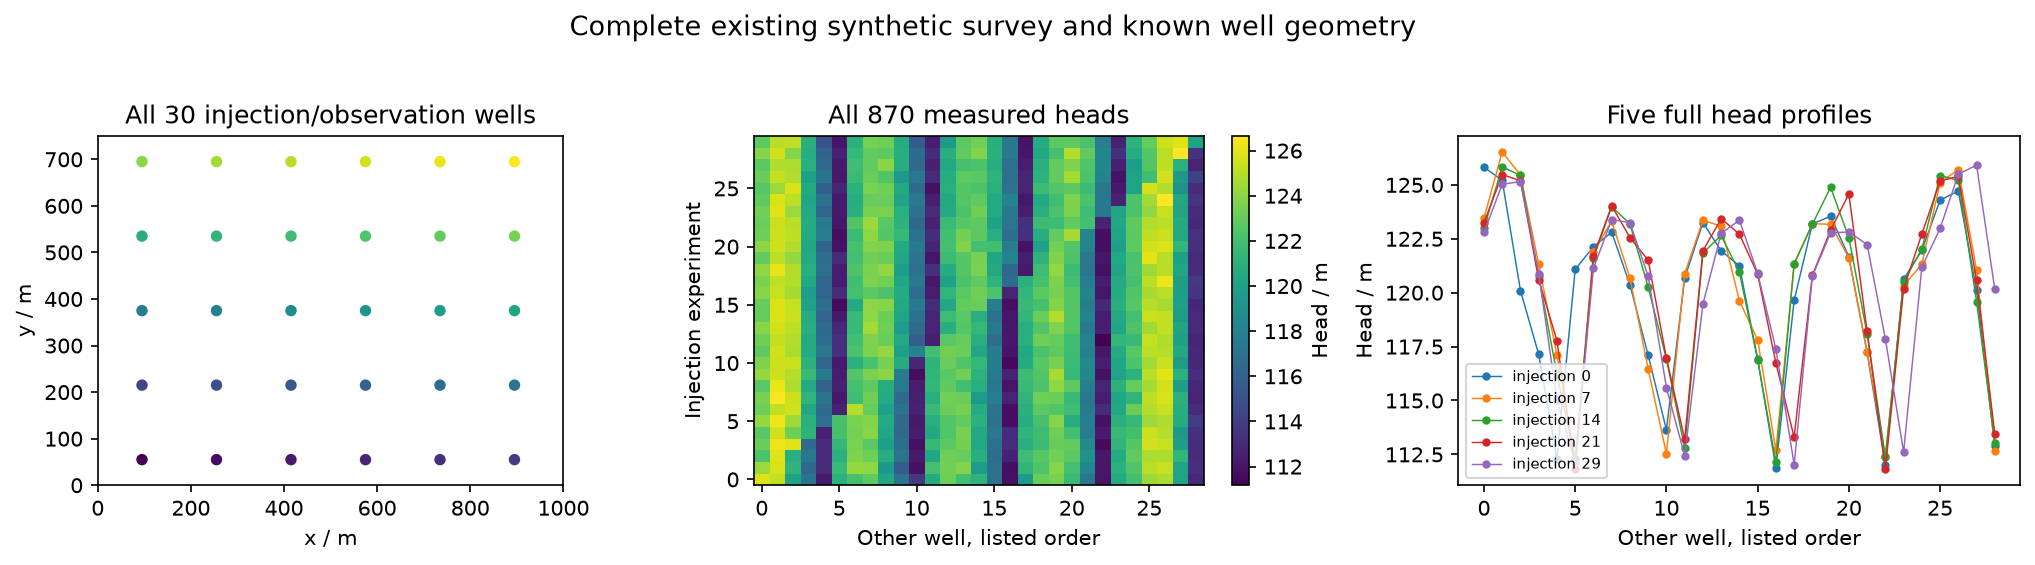

In [2]:
observed,wells=prepare(raw);fig,ax=plt.subplots(1,3,figsize=(14,3.8))
xy=(wells[:,::-1]+.5)*10
ax[0].scatter(xy[:,0],xy[:,1],s=20,c=np.arange(30),cmap='viridis');ax[0].set_xlim(0,1000);ax[0].set_ylim(0,750);ax[0].set_aspect('equal');ax[0].set_xlabel('x / m');ax[0].set_ylabel('y / m');ax[0].set_title('All 30 injection/observation wells')
im=ax[1].imshow(raw['hydraulic_head'][0],origin='lower',aspect='auto',cmap='viridis');fig.colorbar(im,ax=ax[1],label='Head / m');ax[1].set_xlabel('Other well, listed order');ax[1].set_ylabel('Injection experiment');ax[1].set_title('All 870 measured heads')
for i in [0,7,14,21,29]:ax[2].plot(raw['hydraulic_head'][0,i],'.-',lw=.7,label=f'injection {i}')
ax[2].set_xlabel('Other well, listed order');ax[2].set_ylabel('Head / m');ax[2].legend(fontsize=7);ax[2].set_title('Five full head profiles')
show(fig,'figure1_survey',dict(heads=raw['hydraulic_head'],wells=wells,coordinates=xy),'Complete existing synthetic survey and known well geometry')


## Physics
For conductivity $K$ in m/day and thickness $b=1$m, harmonic face conductance gives $\sum_j c_{ij}(h_i-h_j)=r_0 A_i+Q_i$. Here $h$ is head in m, $c$ conductance in m²/day, $r_0$ recharge in m/day, $A_i=100$m²cell area and $Q_i$ injected volume per day. Constant head columns are eliminated into the right-hand side; transverse exterior faces have zero flux. All30right-hand sides share one coefficient matrix. The local implementation constructs this finite-volume operator explicitly, without a groundwater reconstruction library.

The log-field covariance $Q_{ij}=\exp(-d_{ij}/200\mathrm{m})$ expresses a conditional spatial prior, where $d_{ij}$ is cell separation. A reflected circulant embedding evaluates this covariance by general FFT primitives. Retaining50leading eigenpairs is the selected low-rank approximation. Forward head serialization and directional derivative precision follow the legacy source and have independent backend tolerances.


## Method
For $s=\log(K/(1\mathrm{m/day}))$, observations $y$ and predicted heads $f(s)$, minimize $\Phi=\tfrac12(y-f)^TR^{-1}(y-f)+\tfrac12\|\Lambda^{-1/2}U^T(s-X\beta)\|^2$. Here $R=.25I$ m², $U,\Lambda$ are retained covariance eigenpairs, $X$ is the unit-norm constant column and $\beta$ its unknown mean coefficient. Finite differences supply $HX,HZ,Hs$, where $Z=U\Lambda^{1/2}$ and $H$ is the forward Jacobian. Each damped co-kriging step solves a saddle system and all24candidates are evaluated nonlinearly. Extrapolating line search and source relative-change/nonprogress rules select the returned best field.

The source's matrix-free Krylov solve and the local Schur/Woodbury expression solve the same system. An independent source-candidate check gave relative4.79×10⁻¹¹agreement before extraction. No observation-derived inverse field or frozen basis is loaded by the runtime. The full fresh reconstruction below must meet the source-only frozen truth and observation criteria.


{
  "runtime_seconds": 20.906876599998213,
  "best_iteration": 7,
  "metrics": {
    "ncc": 0.9967930225369562,
    "nrmse": 0.04846226553051235,
    "forward_head_rms": 0.4920785967437012
  }
}


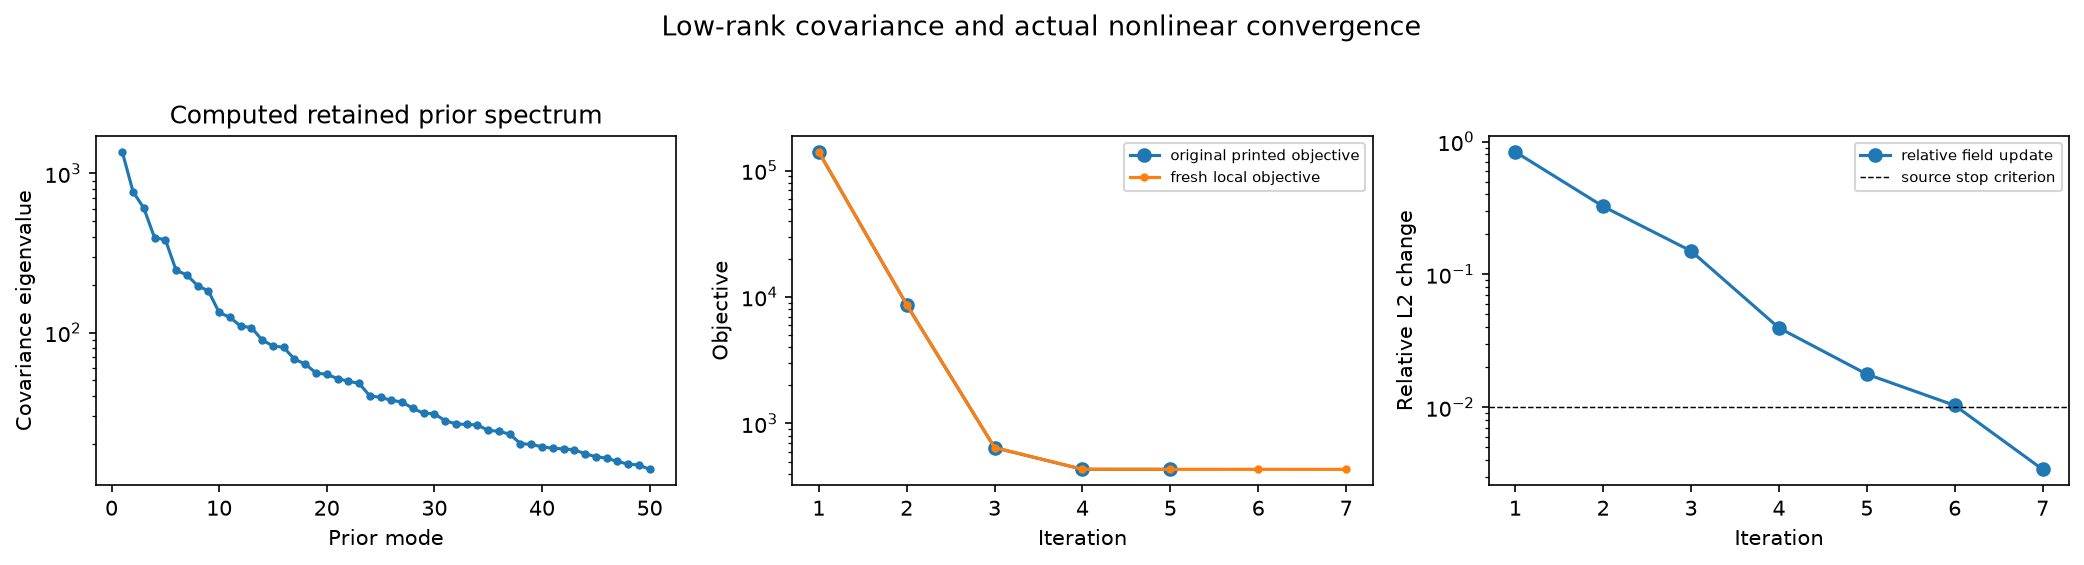

In [3]:
start=time.perf_counter();fresh=reconstruct(raw);runtime=time.perf_counter()-start;field=fresh['reconstruction'][0]
np.savez_compressed(ROOT/'output/reconstruction.npz',reconstruction=fresh['reconstruction'])
spec=importlib.util.spec_from_file_location('independent_judge',ROOT/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report=judge.evaluate(ROOT/'output/reconstruction.npz');assert report['passed'],report
(ROOT/'output/judge_report.json').write_text(json.dumps(report,indent=2),encoding='utf8')
print(json.dumps(dict(runtime_seconds=runtime,best_iteration=fresh['best_iteration'],metrics=report['metrics']),indent=2))
fig,ax=plt.subplots(1,3,figsize=(14,3.8))
ax[0].semilogy(np.arange(1,len(fresh['eigenvalues'])+1),fresh['eigenvalues'],'o-',ms=3);ax[0].set_xlabel('Prior mode');ax[0].set_ylabel('Covariance eigenvalue');ax[0].set_title('Computed retained prior spectrum')
ax[1].semilogy(np.arange(1,len(original_q)+1),original_q,'o-',label='original printed objective');ax[1].semilogy([r['iteration'] for r in fresh['trace']],[r['objective'] for r in fresh['trace']],'.-',label='fresh local objective');ax[1].set_xlabel('Iteration');ax[1].set_ylabel('Objective');ax[1].legend(fontsize=7)
ax[2].semilogy([r['iteration'] for r in fresh['trace']],[r.get('relative_change',np.nan) for r in fresh['trace']],'o-',label='relative field update');ax[2].axhline(.01,color='k',ls='--',lw=.7,label='source stop criterion');ax[2].set_xlabel('Iteration');ax[2].set_ylabel('Relative L2 change');ax[2].legend(fontsize=7)
show(fig,'figure2_method',dict(eigenvalues=fresh['eigenvalues'],source_objective=original_q,objective=np.array([r['objective'] for r in fresh['trace']]),relative_change=np.array([r.get('relative_change',np.nan) for r in fresh['trace']])),'Low-rank covariance and actual nonlinear convergence')


## Results
The source and local estimates are compared with the actual author simulation target in natural-log conductivity units. No field registration, amplitude fitting or difficult-cell mask is used. Numerical head quantization affects finite differences and stopping: the independently reproduced source takes5updates while this local backend takes7. Independent source repeats and author-double-backend diagnostics established the nonzero method-parity window before local scoring. Truth recovery and full-observation fit remain separate requirements.


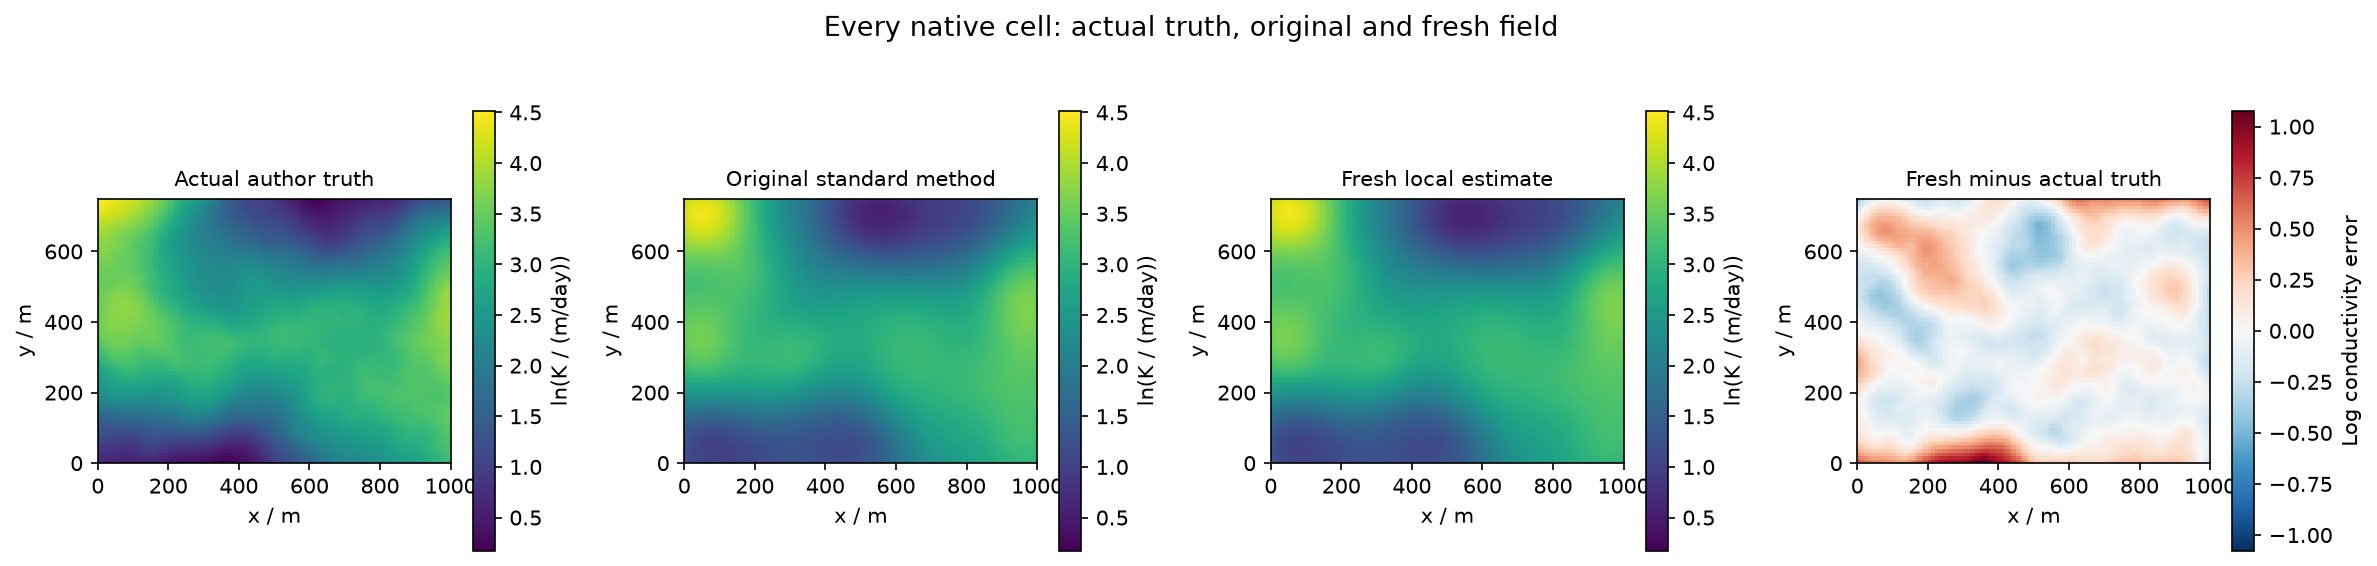

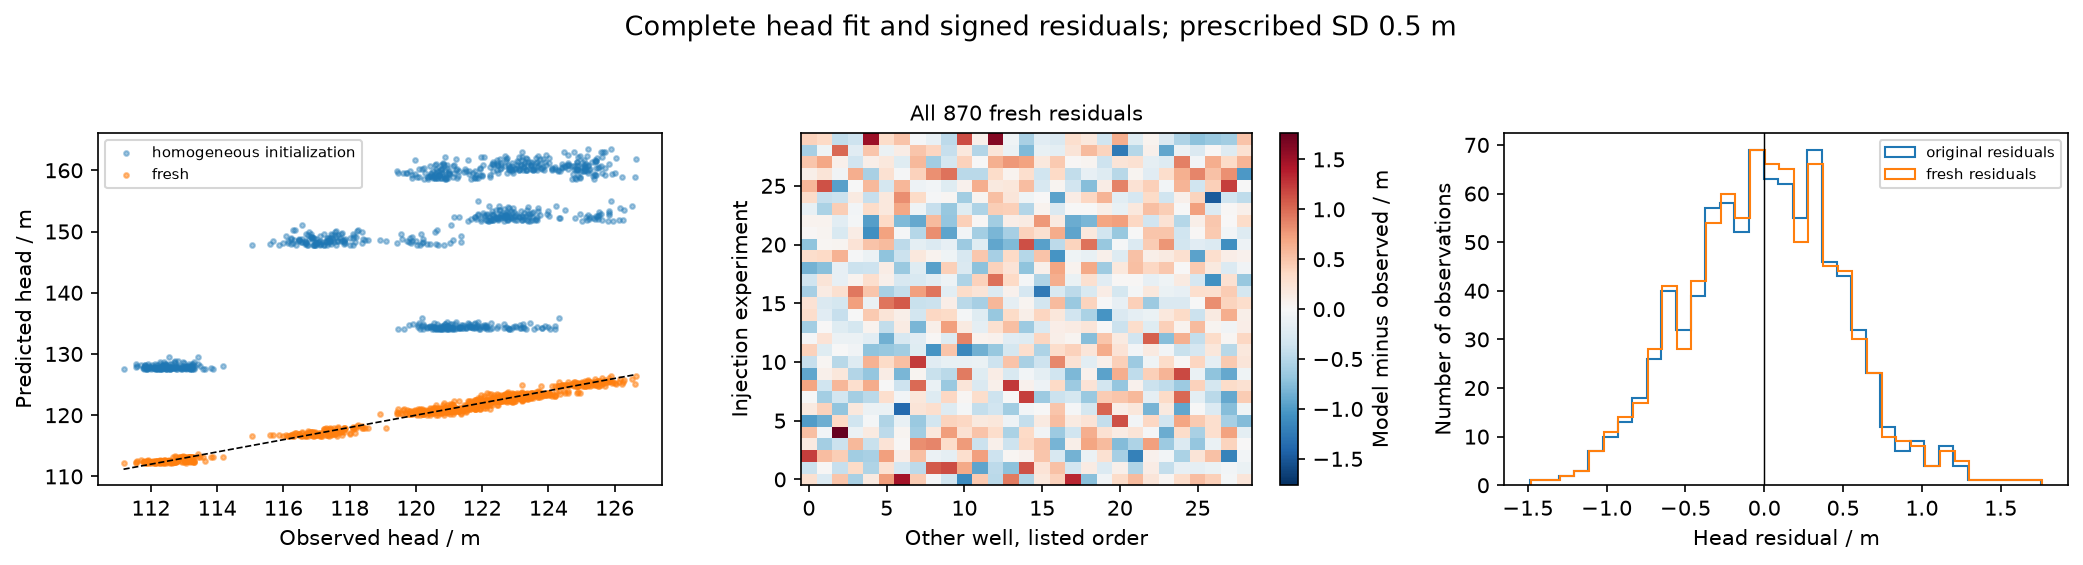

In [4]:
fig,ax=plt.subplots(1,4,figsize=(16,3.8));low=min(truth.min(),field.min(),original['reconstruction'].min());high=max(truth.max(),field.max(),original['reconstruction'].max())
for a,arr,title in zip(ax[:3],[truth,original['reconstruction'][0],field],['Actual author truth','Original standard method','Fresh local estimate']):
    im=a.imshow(arr,origin='lower',extent=extent,cmap='viridis',vmin=low,vmax=high);a.set_title(title,fontsize=10);fig.colorbar(im,ax=a,label='ln(K / (m/day))')
im=image_panel(ax[3],field-truth,'Fresh minus actual truth',extent=extent,signed=True);fig.colorbar(im,ax=ax[3],label='Log conductivity error')
for a in ax:a.set_xlabel('x / m');a.set_ylabel('y / m');a.set_aspect('equal')
show(fig,'figure3_fields',dict(truth=truth,original=original['reconstruction'][0],fresh=field,error=field-truth,source_error=field-original['reconstruction'][0]),'Every native cell: actual truth, original and fresh field')
fig,ax=plt.subplots(1,3,figsize=(14,3.8));pred=fresh['predicted_heads'].ravel();source_pred=original['hydraulic_heads'].ravel();residual=pred-observed
ax[0].scatter(observed,fresh['initial_heads'].ravel(),s=5,alpha=.4,label='homogeneous initialization');ax[0].scatter(observed,pred,s=5,alpha=.5,label='fresh');bounds=[min(observed.min(),pred.min()),max(observed.max(),pred.max())];ax[0].plot(bounds,bounds,'k--',lw=.8);ax[0].set_xlabel('Observed head / m');ax[0].set_ylabel('Predicted head / m');ax[0].legend(fontsize=7)
im=image_panel(ax[1],residual.reshape(30,29),'All 870 fresh residuals',signed=True);fig.colorbar(im,ax=ax[1],label='Model minus observed / m');ax[1].set_xlabel('Other well, listed order');ax[1].set_ylabel('Injection experiment')
ax[2].hist(source_pred-observed,bins=35,histtype='step',label='original residuals');ax[2].hist(residual,bins=35,histtype='step',label='fresh residuals');ax[2].axvline(0,color='k',lw=.7);ax[2].set_xlabel('Head residual / m');ax[2].set_ylabel('Number of observations');ax[2].legend(fontsize=7)
show(fig,'figure4_observations',dict(observed=observed,fresh=pred,original=source_pred,initial=fresh['initial_heads'],residual=residual),'Complete head fit and signed residuals; prescribed SD 0.5 m')


The original variance helper omits the lower-input terms of its claimed saddle inverse. An independent small-matrix inversion proves the omission. We retain its reported array as a source variance diagnostic and compute the complete unknown-mean conditional covariance separately. This comparison preserves the source uncertainty discussion while exposing the approximation. Neither map is a measured error distribution or geological uncertainty calibration. Both use the source's last-linearization convention; the complete formula retains legitimate values above unit prior variance when present.


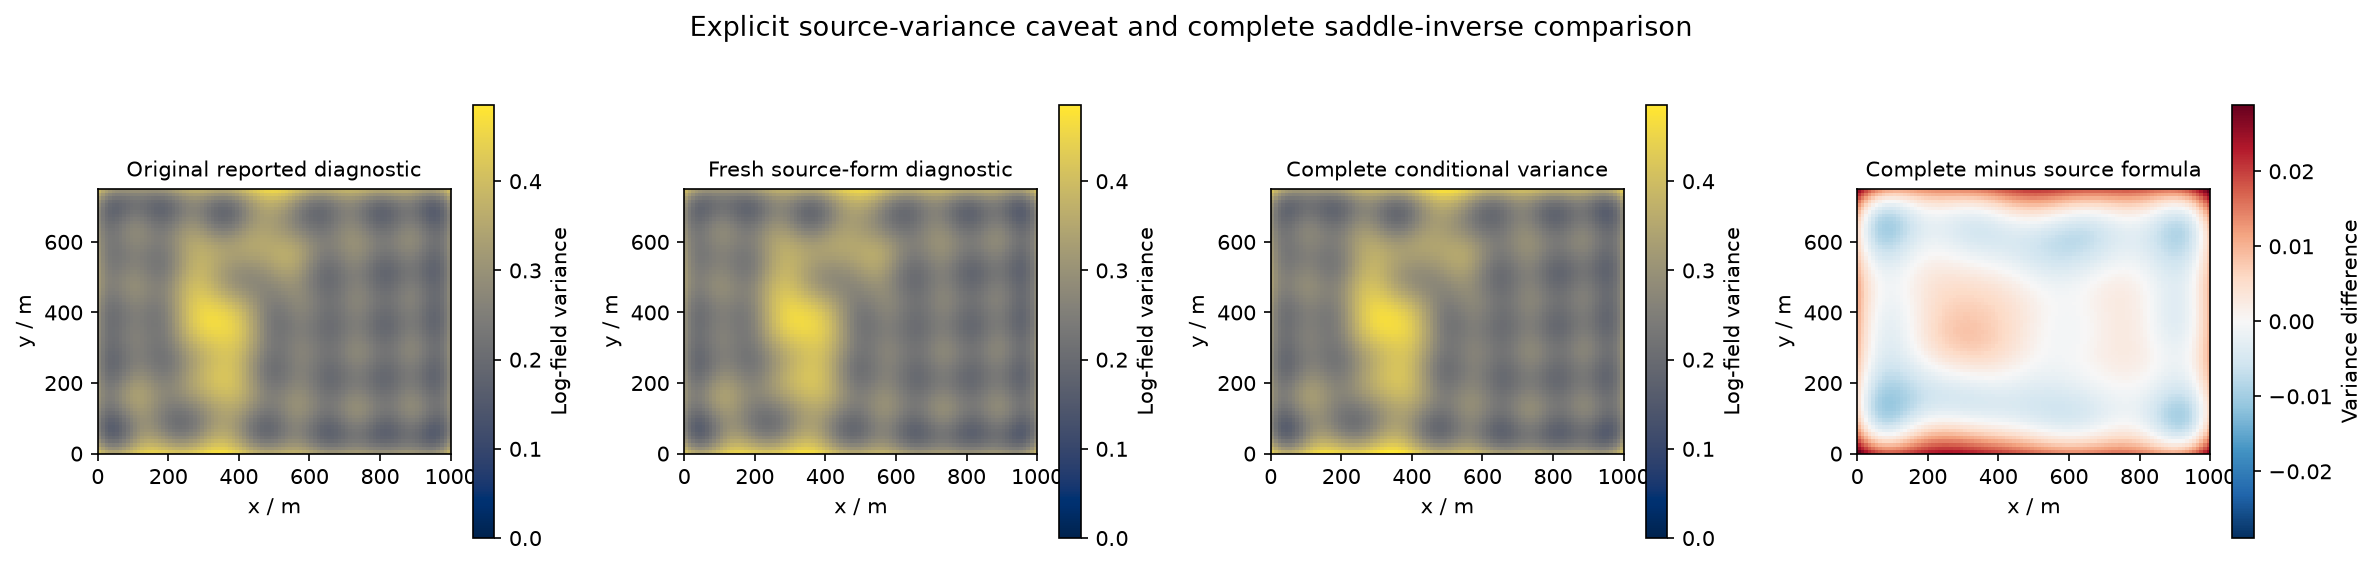

In [5]:
fig,ax=plt.subplots(1,4,figsize=(16,3.8));sv=fresh['source_variance_diagnostic'][0];cv=fresh['conditional_variance'][0];ov=original['posterior_diagonal'][0];upper=max(sv.max(),cv.max(),ov.max())
for a,arr,title in zip(ax[:3],[ov,sv,cv],['Original reported diagnostic','Fresh source-form diagnostic','Complete conditional variance']):
    im=a.imshow(arr,origin='lower',extent=extent,vmin=0,vmax=upper,cmap='cividis');a.set_title(title,fontsize=10);fig.colorbar(im,ax=a,label='Log-field variance')
im=image_panel(ax[3],cv-sv,'Complete minus source formula',extent=extent,signed=True);fig.colorbar(im,ax=ax[3],label='Variance difference')
for a in ax:a.set_xlabel('x / m');a.set_ylabel('y / m');a.set_aspect('equal')
show(fig,'figure5_uncertainty',dict(original_reported=ov,fresh_source_diagnostic=sv,complete_conditional_variance=cv,difference=cv-sv),'Explicit source-variance caveat and complete saddle-inverse comparison')


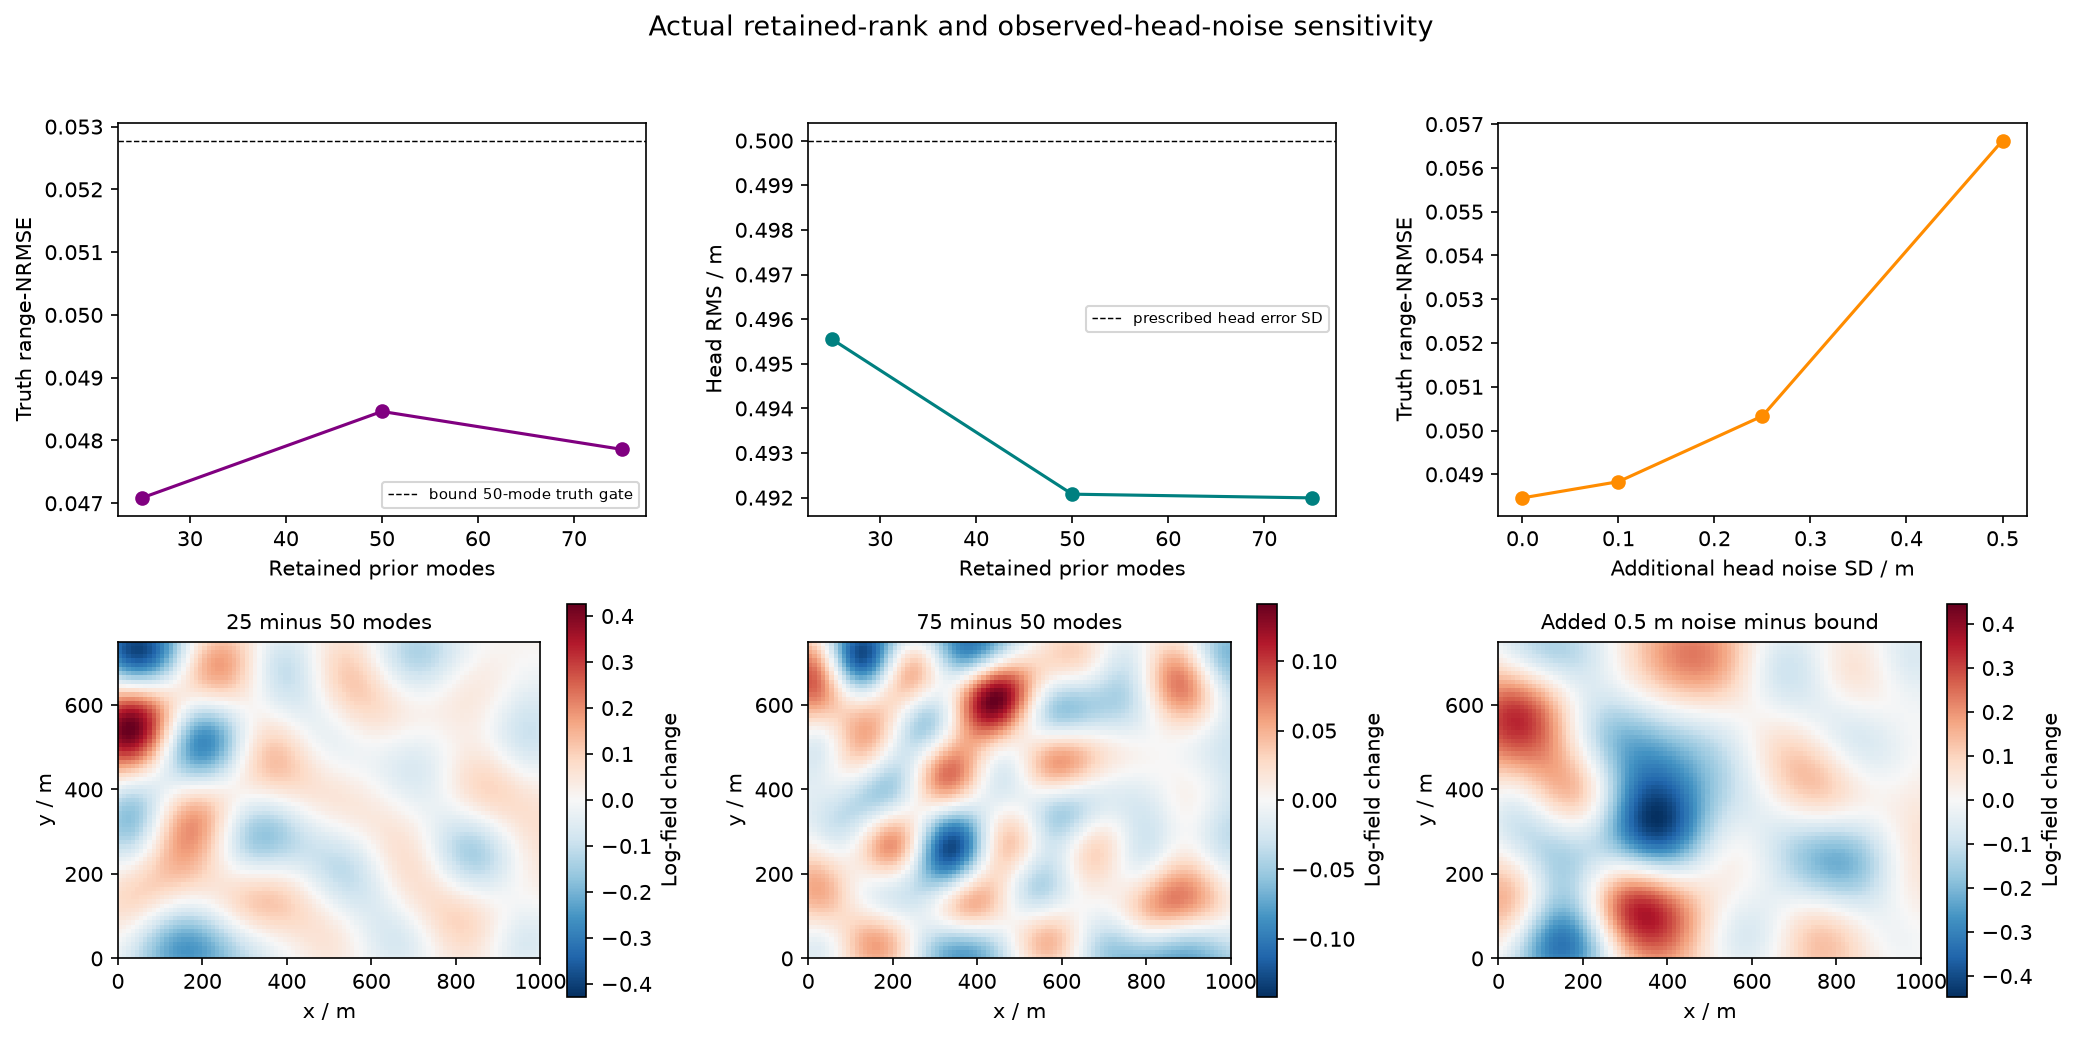

{
  "runtime_seconds": 20.906876599998213,
  "best_iteration": 7,
  "metrics": {
    "ncc": 0.9967930225369562,
    "nrmse": 0.04846226553051235,
    "forward_head_rms": 0.4920785967437012
  },
  "mode_truth_error": [
    0.04708516148679895,
    0.04846226553051234,
    0.04785781060200673
  ],
  "mode_head_rms": [
    0.49554724848800735,
    0.4920785967437012,
    0.49199557530060395
  ],
  "additional_noise_m": [
    0,
    0.1,
    0.25,
    0.5
  ],
  "noise_truth_error": [
    0.04846226553051234,
    0.048832808895849185,
    0.050332960158248174,
    0.05662437856681866
  ],
  "noise_seed": 124,
  "source_variance_relative_l2": 0.005080609419907476
}


In [6]:
modes=[25,50,75];mode_results=[]
for n in modes:mode_results.append(fresh if n==50 else reconstruct(raw,n_modes=n))
mode_error=np.array([metrics(r['reconstruction'][0])[1] for r in mode_results]);mode_heads=np.array([np.sqrt(np.mean((r['predicted_heads']-raw['hydraulic_head'])**2)) for r in mode_results])
noise=[0,.1,.25,.5];noise_results=[]
for sigma in noise:noise_results.append(fresh if sigma==0 else reconstruct(perturb_heads(raw,sigma,seed=124)))
noise_error=np.array([metrics(r['reconstruction'][0])[1] for r in noise_results])
fig,ax=plt.subplots(2,3,figsize=(14,7))
ax[0,0].plot(modes,mode_error,'o-',color='purple');ax[0,0].axhline(.052777390088457304,color='k',ls='--',lw=.7,label='bound 50-mode truth gate');ax[0,0].set_xlabel('Retained prior modes');ax[0,0].set_ylabel('Truth range-NRMSE');ax[0,0].legend(fontsize=7)
ax[0,1].plot(modes,mode_heads,'o-',color='teal');ax[0,1].axhline(.5,color='k',ls='--',lw=.7,label='prescribed head error SD');ax[0,1].set_xlabel('Retained prior modes');ax[0,1].set_ylabel('Head RMS / m');ax[0,1].legend(fontsize=7)
ax[0,2].plot(noise,noise_error,'o-',color='darkorange');ax[0,2].set_xlabel('Additional head noise SD / m');ax[0,2].set_ylabel('Truth range-NRMSE')
for a,arr,title in zip(ax[1],[mode_results[0]['reconstruction'][0]-field,mode_results[-1]['reconstruction'][0]-field,noise_results[-1]['reconstruction'][0]-field],['25 minus 50 modes','75 minus 50 modes','Added 0.5 m noise minus bound']):
    im=image_panel(a,arr,title,extent=extent,signed=True);fig.colorbar(im,ax=a,label='Log-field change');a.set_xlabel('x / m');a.set_ylabel('y / m');a.set_aspect('equal')
show(fig,'figure6_sensitivity',dict(modes=np.array(modes),mode_fields=np.array([r['reconstruction'][0] for r in mode_results]),mode_truth_error=mode_error,mode_head_rms=mode_heads,additional_noise_m=np.array(noise),noise_fields=np.array([r['reconstruction'][0] for r in noise_results]),noise_truth_error=noise_error),'Actual retained-rank and observed-head-noise sensitivity')
summary=dict(runtime_seconds=runtime,best_iteration=fresh['best_iteration'],metrics=report['metrics'],mode_truth_error=mode_error.tolist(),mode_head_rms=mode_heads.tolist(),additional_noise_m=noise,noise_truth_error=noise_error.tolist(),noise_seed=124,source_variance_relative_l2=float(np.linalg.norm(sv-ov)/np.linalg.norm(ov)))
(FIG/'notebook_measurements.json').write_text(json.dumps(summary,indent=2),encoding='utf8');print(json.dumps(summary,indent=2))


## Conclusion
The complete local hydraulic inverse passes independently frozen field-truth, source-parity and full-observation criteria. Rank and added-head-noise experiments are actual computations. A unit-conductivity initialization or a constant field cannot meet the spatial error requirement. The source-reported variance diagnostic and the complete conditional covariance are distinguished explicitly.

The spatial prior, finite mode count and known-boundary model limit resolution. Additional-noise experiments retain the original assumed observation variance and therefore also probe error-model mismatch. The source paper's different exact fields, adjoint textbook arrays and tracer observations are unavailable for this selected author adaptation and are not fabricated as fresh comparisons. Simulation truth is known only for this example; neither convergence nor covariance maps establishes equivalent accuracy in an actual aquifer.
